# 03 - Feature Engineering

**Goal:** create new columns that help the model and turn text into numbers.

**Input:** `data/processed/housing_clean.csv`  |  **Output:** `data/processed/housing_features.csv`

### Tasks in this notebook
- [x] Create rooms per household
- [x] Create bedrooms per room
- [x] Create population per household
- [x] One-hot encode `ocean_proximity`
- [x] Check how the new features correlate with price
- [x] Save the feature-ready dataset

*Feature scaling happens in notebook 04, after the train/test split, to avoid data leakage.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
IMAGE_DIR = Path('../images')
OUT_PATH = Path('../data/processed/housing_features.csv')

df = pd.read_csv('../data/processed/housing_clean.csv')
print(df.shape)

(19642, 14)


## 1. New ratio features
Raw totals depend on how big a block is. Ratios describe the *kind* of neighborhood, which is more useful. These are **vectorized** operations: pandas does the math on whole columns at once, with no loops.

In [2]:
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].describe().round(2)

,rooms_per_household,bedrooms_per_room,population_per_household
count,19642.00,19642.00,19642.00
mean,5.36,0.22,3.10
std,2.29,0.06,10.64
min,0.85,0.04,0.69
25%,4.41,0.18,2.45
50%,5.18,0.20,2.84
75%,5.97,0.24,3.31
max,132.53,2.82,1243.33


## 2. One-hot encoding of `ocean_proximity`
Models need numbers. One-hot encoding turns each category into its own 0/1 column.

In [3]:
df = pd.get_dummies(df, columns=['ocean_proximity'], dtype=int)
print([c for c in df.columns if c.startswith('ocean_proximity_')])
df.filter(like='ocean_proximity_').head()

['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0,0,0,1,0
1,0,0,0,1,0
2,0,0,0,1,0
3,0,0,0,1,0
4,0,0,0,1,0


## 3. Drop the raw count columns
We now have `_log` versions (less skewed) and ratios, so the raw totals are redundant. Keeping both would add duplicated information.

In [4]:
raw_counts = ['total_rooms', 'total_bedrooms', 'population', 'households']
df = df.drop(columns=raw_counts)
print('Columns now:')
print(list(df.columns))

Columns now:
['longitude', 'latitude', 'housing_median_age', 'median_income', 'median_house_value', 'total_rooms_log', 'total_bedrooms_log', 'population_log', 'households_log', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


## 4. Do the new features help?
Correlation with the target, strongest first.

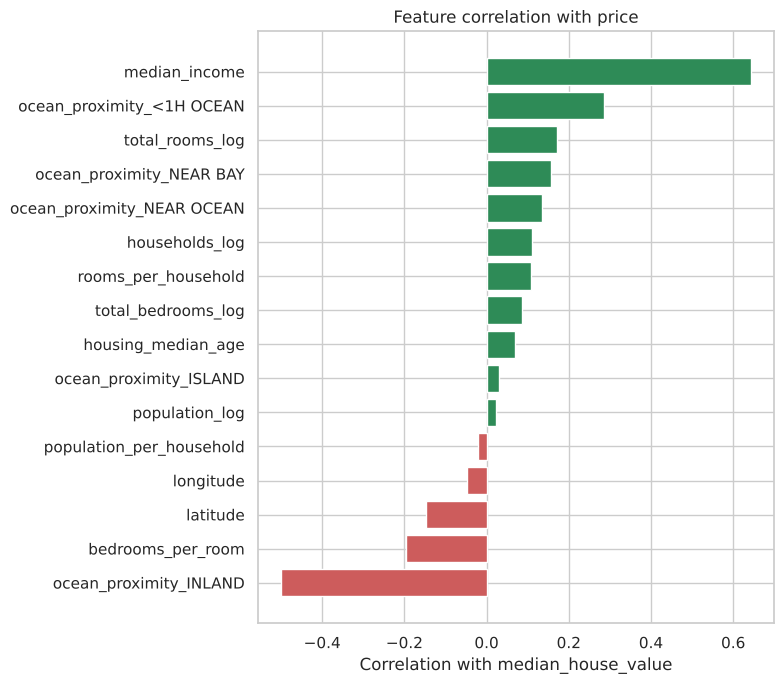

median_income                 0.642
ocean_proximity_<1H OCEAN     0.284
total_rooms_log               0.172
ocean_proximity_NEAR BAY      0.157
ocean_proximity_NEAR OCEAN    0.136
households_log                0.111
rooms_per_household           0.109
total_bedrooms_log            0.086
housing_median_age            0.069
ocean_proximity_ISLAND        0.031
population_log                0.023
population_per_household     -0.021
longitude                    -0.047
latitude                     -0.148
bedrooms_per_room            -0.196
ocean_proximity_INLAND       -0.499
Name: median_house_value, dtype: float64

In [5]:
corr_target = df.corr()['median_house_value'].drop('median_house_value').sort_values()

plt.figure(figsize=(8, 7))
colors = ['indianred' if v < 0 else 'seagreen' for v in corr_target]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.xlabel('Correlation with median_house_value')
plt.title('Feature correlation with price')
plt.tight_layout()
plt.savefig(IMAGE_DIR / '07_feature_correlation.png', dpi=120, bbox_inches='tight')
plt.show()

corr_target.sort_values(ascending=False).round(3)

## 5. Save the feature-ready dataset

In [6]:
df.to_csv(OUT_PATH, index=False)
print('Saved to', OUT_PATH, '| shape:', df.shape)

Saved to ../data/processed/housing_features.csv | shape: (19642, 17)


## 6. Check your work

In [7]:
check = pd.read_csv(OUT_PATH)
assert check.isna().sum().sum() == 0, 'Missing values found'
assert np.isfinite(check.select_dtypes('number').to_numpy()).all(), 'Infinite values found'
assert check.select_dtypes(exclude='number').shape[1] == 0, 'Non-numeric columns remain'
assert {'rooms_per_household', 'bedrooms_per_room', 'population_per_household'} <= set(check.columns)
print(f'Notebook 03 checks passed ({check.shape[1]} columns). Next: 04_modeling.ipynb')

Notebook 03 checks passed (17 columns). Next: 04_modeling.ipynb
